# Estimating the temperature of a star

**Probability, model fitting, and Bayesian inference**

Generate a noisy stellar spectrum and estimate its temperature. The second question is how the estimate changes when only part of the spectrum is measured. We treat the star as a blackbody and fit an unknown overall brightness as well as temperature. The brightness absorbs the star's size and distance; the *shape* carries information about temperature.

All data here are simulated. The blackbody, flat measurement noise, and independent data points are deliberate simplifications.

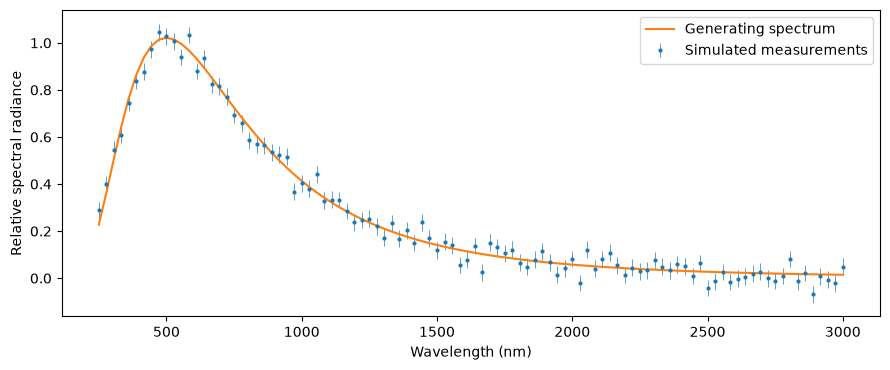

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(82)
h = 6.62607015e-34   # J s
c = 2.99792458e8     # m/s
kB = 1.380649e-23    # J/K

def planck(wavelength_nm, temperature):
    # Planck's law uses metres; convert the input wavelengths from nm.
    wavelength = np.asarray(wavelength_nm)*1e-9
    x = h*c/(wavelength*kB*temperature)
    
    # expm1(x) evaluates exp(x)-1 accurately when x is small.
    return 2*h*c*c/(wavelength**5 * np.expm1(x))

reference = planck(550, 5800)  # fixed scaling; cancels physical units

def spectrum(wavelength_nm, temperature):
    return planck(wavelength_nm, temperature)/reference

wavelengths = np.linspace(250, 3000, 100)
true_temperature = 5800
true_brightness = 1.0
noise_sigma = 0.035 * np.max(spectrum(wavelengths, true_temperature))
measured = true_brightness*spectrum(wavelengths, true_temperature)
measured += rng.normal(0, noise_sigma, size=len(wavelengths))

plt.figure(figsize=(9, 3.8))
plt.errorbar(wavelengths, measured, yerr=noise_sigma, fmt='.', ms=4,
             lw=0.5, label='Simulated measurements')
plt.plot(wavelengths, true_brightness*spectrum(wavelengths, true_temperature),
         label='Generating spectrum', lw=1.5)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Relative spectral radiance')
plt.legend()
plt.tight_layout()
plt.show()

**Takeaway:** The simulated measurements scatter around a blackbody curve. The range includes the peak and part of the tail, so the fit can use changes in shape as well as overall brightness.

## Fit a temperature and brightness

Planck's law gives $B_\lambda(T)=2hc^2/[\lambda^5(\exp(hc/(\lambda k_BT))-1)]$. Our prediction is $m_i=A B_{\lambda_i}(T)/B_{550\mathrm{nm}}(5800\mathrm K)$. We assume independent Gaussian errors with known standard deviation $\sigma$:

$$\log p(D\mid T,A)=-\frac{1}{2\sigma^2}\sum_i [y_i-m_i(T,A)]^2+\text{constant}.$$

Use uniform priors $3500\leq T\leq8500$ K and $0.5\leq A\leq1.5$. Evaluate the joint posterior on a rectangular grid; sum over brightness to obtain the temperature posterior. Here the same priors and noise level apply to all wavelength selections.

In [2]:

def midpoint_grid(lower, upper, count):
    # Each grid point represents one equal-width cell inside the prior bounds.
    edges = np.linspace(lower, upper, count + 1)
    
    return (edges[:-1] + edges[1:]) / 2, edges

def central_interval(mass, edges):
    # Interpolate the cumulative mass at cell edges (uniform within each cell).
    cdf = np.r_[0, np.cumsum(mass)]
    cdf[-1] = 1.0
    
    return np.interp([0.025, 0.975], cdf, edges)

temperatures, temperature_edges = midpoint_grid(3500, 8500, 501)
brightnesses, brightness_edges = midpoint_grid(0.5, 1.5, 201)

def fit_range(mask):
    wave = wavelengths[mask]
    data = measured[mask]
    
    # One row per temperature, one column per selected wavelength.
    shapes = spectrum(wave[None, :], temperatures[:, None])
    
    # Quadratic form saves constructing a T x A x wavelength array.
    yy = np.sum(data**2)
    sy = shapes @ data
    ss = np.sum(shapes**2, axis=1)
    chi2 = (yy - 2*sy[:, None]*brightnesses[None, :]
            + ss[:, None]*brightnesses[None, :]**2)/noise_sigma**2
    
    # Subtract the best chi-square before exponentiating; the scale cancels.
    likelihood = np.exp(-0.5*(chi2 - np.min(chi2)))
    joint = likelihood/np.sum(likelihood)
    
    # Average out brightness by summing the joint mass over its columns.
    pT = np.sum(joint, axis=1)
    pA = np.sum(joint, axis=0)
    center = np.sum(temperatures*pT)
    interval = central_interval(pT, temperature_edges)
    
    return {'joint': joint, 'pT': pT, 'pA': pA,
            'mean_T': center, 'interval': interval,
            'mean_A': np.sum(brightnesses*pA), 'count': len(wave)}

ranges = {
    'All wavelengths (250–3000 nm)': np.ones(len(wavelengths), dtype=bool),
    'Visible only (400–700 nm)': (wavelengths >= 400) & (wavelengths <= 700),
    'Infrared only (1300–2800 nm)': (wavelengths >= 1300) & (wavelengths <= 2800),
}

fits = {name: fit_range(mask) for name, mask in ranges.items()}

for name, fit in fits.items():
    lo, hi = fit['interval']
    print(f'{name:34s} n={fit["count"]:2d}   T={fit["mean_T"]:.0f} K   '
          f'95% interval [{lo:.0f}, {hi:.0f}] K   brightness={fit["mean_A"]:.3f}')

All wavelengths (250–3000 nm)      n=100   T=5805 K   95% interval [5736, 5875] K   brightness=0.989
Visible only (400–700 nm)          n=11   T=5724 K   95% interval [5546, 5909] K   brightness=1.062
Infrared only (1300–2800 nm)       n=54   T=6272 K   95% interval [4875, 8249] K   brightness=0.944


## Which wavelengths constrain temperature?

Compare the temperature posteriors directly. Their peak positions change with random noise, while the interval widths indicate how much each wavelength range has learned under this model. Near the long-wavelength tail, changing brightness can imitate much of the change caused by temperature, making the infrared-only result less informative.

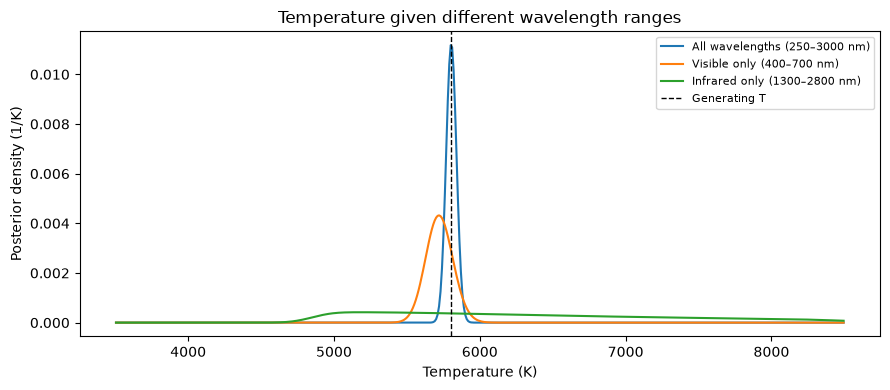

In [3]:
plt.figure(figsize=(9, 4))

for name, fit in fits.items():
    plt.plot(temperatures, fit['pT']/(temperatures[1]-temperatures[0]), label=name)

plt.axvline(true_temperature, ls='--', color='black', lw=1, label='Generating T')
plt.xlabel('Temperature (K)')
plt.ylabel('Posterior density (1/K)')
plt.title('Temperature given different wavelength ranges')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Takeaway:** The infrared-only curve is broader in this run because temperature and brightness are harder to separate on the tail. The selections also have different numbers of points, so this is not a matched-size comparison.

## Joint uncertainty and fit to the data

The two fitted parameters can trade off. Plot their joint posterior for broad coverage and for infrared-only data. Then compare a representative fitted spectrum from the broad-range posterior with the measurements, and inspect residuals in units of $\sigma$. The posterior means form a convenient illustrative curve; they are not guaranteed to be the most likely parameter pair.

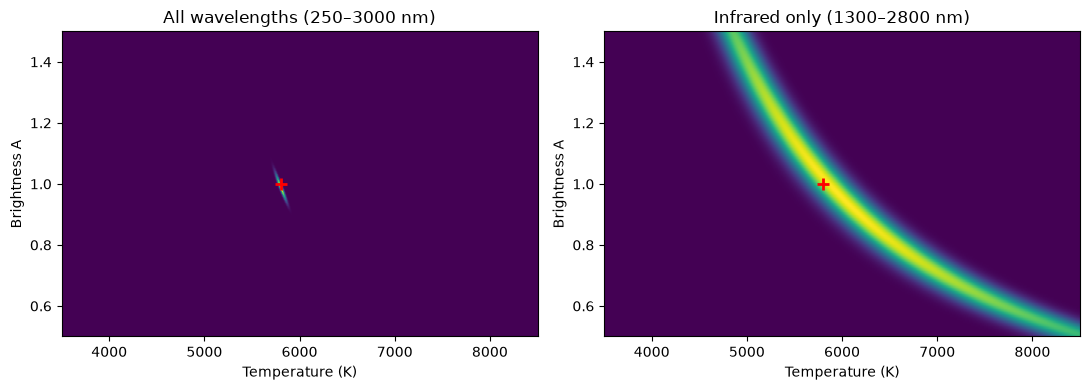

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name in zip(axes, ['All wavelengths (250–3000 nm)',
                           'Infrared only (1300–2800 nm)']):
    ax.imshow(fits[name]['joint'].T, origin='lower', aspect='auto',
              extent=[temperature_edges[0], temperature_edges[-1],
                      brightness_edges[0], brightness_edges[-1]], cmap='viridis')
    ax.plot(true_temperature, true_brightness, 'r+', ms=9, mew=2)
    ax.set(xlabel='Temperature (K)', ylabel='Brightness A', title=name)
plt.tight_layout()
plt.show()



**Takeaway:** The red cross marks the simulated parameters. The infrared ridge shows that a hotter model can compensate with lower brightness. Each panel uses its own colour scale; compare the shape and spread of the regions.

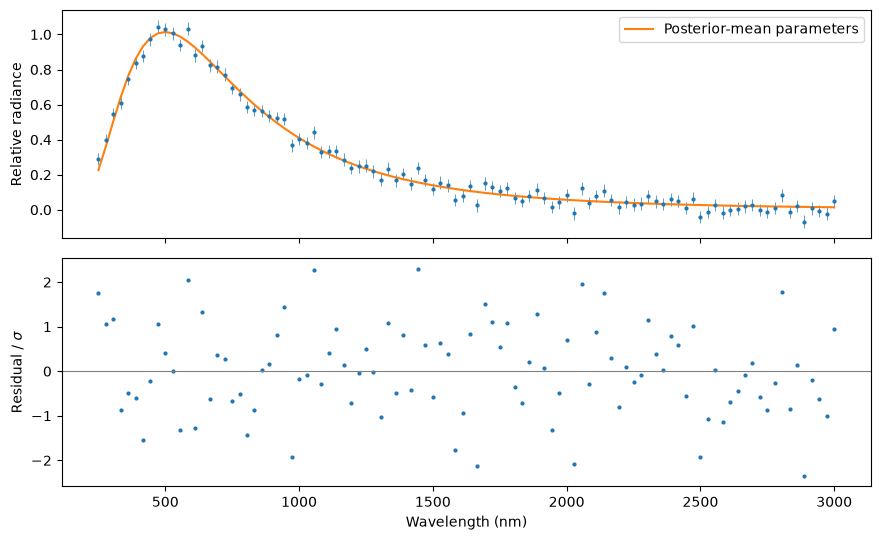

Residual RMS in units of sigma: 1.02


In [5]:
# Evaluate one illustrative curve and express residuals in units of the known noise.
full = fits['All wavelengths (250–3000 nm)']
prediction = full['mean_A']*spectrum(wavelengths, full['mean_T'])
residual = (measured-prediction)/noise_sigma
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].errorbar(wavelengths, measured, yerr=noise_sigma, fmt='.', ms=4, lw=0.5)
axes[0].plot(wavelengths, prediction, label='Posterior-mean parameters')
axes[0].set_ylabel('Relative radiance')
axes[0].legend()
axes[1].plot(wavelengths, residual, '.', ms=4)
axes[1].axhline(0, color='gray', lw=0.8)
axes[1].set(xlabel='Wavelength (nm)', ylabel=r'Residual / $\sigma$')
plt.tight_layout()
plt.show()
print('Residual RMS in units of sigma:', round(np.sqrt(np.mean(residual**2)), 2))

**Takeaway:** Residuals scattered around zero suggest that this representative curve captures the main trend. The plotted error bars show measurement noise; they do not show uncertainty in the fitted spectrum.

## Conclusion

Fitting the full simulated spectrum recovers a temperature range while allowing the overall brightness to remain unknown. Limiting the wavelengths changes both the inferred temperature and its uncertainty. The broad and infrared joint posterior plots show directly how temperature and brightness become harder to separate with limited spectral coverage.

These intervals depend on Planck's law, the chosen priors, and the stated measurement noise. Real stars have absorption lines, dust extinction, instrumental response, and often an uncertain noise level; those effects would need separate models before applying this calculation to observed spectra.